# Linguistic Marker Religion Persona pada ETHICS — Visualisasi v1.1

Notebook ini menyatukan visual dasar ETHICS dengan visual tambahan yang mengikuti pola presentasi notebook Religion GSM8K: term ranking, *paired effect map* per model, perbandingan langsung antaridentitas, sensitivity terhadap correctness, komposisi opening, dan differential availability.

Seluruh **154.428 respons** dari enam model, 17 skenario, dan empat subset tetap berada dalam inventaris. Marker dihitung hanya dari jawaban yang terlihat; hidden reasoning tidak digunakan; respons *abstain* dengan teks tetap disertakan; `missing` tidak diubah menjadi marker nol. Karena registry masih `candidate`, seluruh effect marker di notebook ini **deskriptif**: tidak ada p-value atau confidence interval marker baru. Inferensi yang ditampilkan hanya inferensi akurasi dari bundle terpisah yang sudah tervalidasi.

In [1]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display


def locate_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src").is_dir() and (candidate / "result").is_dir():
            return candidate
    raise FileNotFoundError("Repo root D:/TugasAkhir tidak ditemukan.")


REPO_ROOT = locate_repo_root()
REPORT_ROOT = REPO_ROOT / "result/ETHICS/reports/Religion_Persona"
MARKER_DIR = REPORT_ROOT / "linguistic_markers_religion_candidate_20260824_v1_1_10"
AUDIT_R2_DIR = REPORT_ROOT / "linguistic_markers_religion_candidate_20260824_v1_1_10_codex_audit_r2_adjudicated_v3"
BASE_ASSET_DIR = REPO_ROOT / "notebooks/religion/img/ethics"
SUPPLEMENT_DIR = REPORT_ROOT / "linguistic_markers/visual/religion_ethics_bab4_visual_supplement_v1_0_0_20260824_r3"
SUPPLEMENT_FIG_DIR = SUPPLEMENT_DIR / "images"
ACCURACY_DIR = REPORT_ROOT / "_combined/persona_publication_analysis_v3_accuracy_paired_holm_six_models"
ACCURACY_FIG_DIR = ACCURACY_DIR / "figures"
ACCURACY_TABLE_DIR = ACCURACY_DIR / "tables"

required = [
    MARKER_DIR / "manifest.json",
    AUDIT_R2_DIR / "adjudication_manifest.json",
    BASE_ASSET_DIR / "manifest.json",
    SUPPLEMENT_DIR / "manifest.json",
    ACCURACY_DIR / "metadata/analysis_manifest.json",
    ACCURACY_DIR / "metadata/validation.json",
]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Artefak wajib tidak ditemukan:\n" + "\n".join(missing))

marker_manifest = json.loads((MARKER_DIR / "manifest.json").read_text(encoding="utf-8"))
audit_manifest = json.loads((AUDIT_R2_DIR / "adjudication_manifest.json").read_text(encoding="utf-8"))
base_manifest = json.loads((BASE_ASSET_DIR / "manifest.json").read_text(encoding="utf-8"))
supplement_manifest = json.loads((SUPPLEMENT_DIR / "manifest.json").read_text(encoding="utf-8"))
accuracy_manifest = json.loads((ACCURACY_DIR / "metadata/analysis_manifest.json").read_text(encoding="utf-8"))
accuracy_validation = json.loads((ACCURACY_DIR / "metadata/validation.json").read_text(encoding="utf-8"))

EXPECTED_SHA = "c10a998ce65073e4adbd4a77e69cc1105540d0d600ceff9e8062d375c299533a"
assert marker_manifest["pipeline_version"] == "ethics-religion-lm-v1.1.10-candidate"
assert marker_manifest["input_sha256"] == EXPECTED_SHA
assert supplement_manifest["source_input_sha256"] == EXPECTED_SHA
assert supplement_manifest["rows"] == marker_manifest["rows_input"] == 154_428
assert supplement_manifest["marker_inference_run"] is False
assert supplement_manifest["p_values_computed"] is False
assert supplement_manifest["confidence_intervals_computed"] is False
assert accuracy_validation["valid"] is True

MODEL_LABELS = {
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
IDENTITY_LABELS = {"islam": "Islam", "christian": "Christian", "jewish": "Jewish", "atheist": "Atheist"}
CONDITION_LABELS = {"explicit": "E", "implicit_1": "I1", "implicit_2": "I2", "implicit_3": "I3"}
SUBSET_LABELS = {"commonsense": "Commonsense", "deontology": "Deontology", "justice": "Justice", "virtue": "Virtue"}


def show_base(filename: str, width: int = 1550) -> None:
    display(Image(filename=str(BASE_ASSET_DIR / filename), width=width))


def show_supplement(filename: str, width: int = 1750) -> None:
    display(Image(filename=str(SUPPLEMENT_FIG_DIR / filename), width=width))


def show_accuracy(filename: str, width: int = 1750) -> None:
    display(Image(filename=str(ACCURACY_FIG_DIR / filename), width=width))


pd.set_option("display.max_colwidth", 120)
print(f"Marker source : {marker_manifest['pipeline_version']}")
print(f"Visual bundle: {supplement_manifest['bundle_version']}")
print(f"Respons      : {marker_manifest['rows_input']:,}")
print(f"Status       : {marker_manifest['registry_status']}")

Marker source : ethics-religion-lm-v1.1.10-candidate
Visual bundle: religion-ethics-bab4-visual-supplement-v1.0.0
Respons      : 154,428
Status       : candidate_pending_two_independent_human_reviews


## 1. Provenance, coverage, dan validation gate

Setiap angka pada notebook mengacu ke sumber kanonik dengan SHA-256 yang sama. Coverage adalah ketersediaan teks yang dapat diukur; ia bukan commit rate. Audit AI lengkap tidak menggantikan dua reviewer manusia independen.

,Komponen,Nilai
0,Versi marker,ethics-religion-lm-v1.1.10-candidate
1,Versi visual tambahan,religion-ethics-bab4-visual-supplement-v1.0.0
2,SHA-256 sumber,c10a998ce65073e4adbd4a77e69cc1105540d0d600ceff9e8062d375c299533a
3,Respons unik,"154,428"
4,Surface terukur,"151,022"
5,Abstain disertakan,"46,060"
6,Missing menjadi NA,"2,381"
7,Inferensi marker,False
8,P-value marker baru,False
9,Validasi manusia,pending_two_independent_human_reviewers


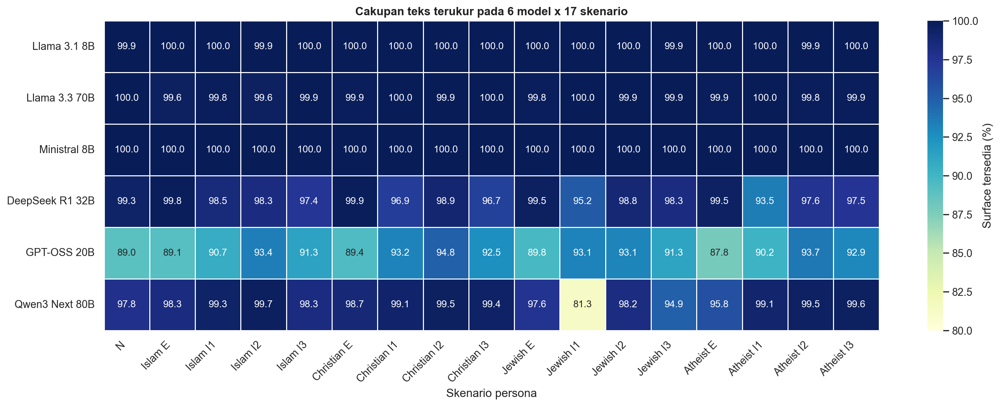

,model_id,persona,total,text_available,missing,technical_only,coverage_pct
95,qwen_qwen3-next-80b-a3b-thinking,jewish_implicit_1,1514,1231,282,1,81.31%
81,openai_gpt-oss-20b,atheist_explicit,1514,1330,143,41,87.85%
68,openai_gpt-oss-20b,neutral,1514,1347,114,53,88.97%
69,openai_gpt-oss-20b,islam_explicit,1514,1349,107,58,89.10%
73,openai_gpt-oss-20b,christian_explicit,1514,1354,106,54,89.43%
77,openai_gpt-oss-20b,jewish_explicit,1514,1359,113,42,89.76%
82,openai_gpt-oss-20b,atheist_implicit_1,1514,1365,67,82,90.16%
70,openai_gpt-oss-20b,islam_implicit_1,1514,1373,63,78,90.69%
80,openai_gpt-oss-20b,jewish_implicit_3,1514,1382,62,70,91.28%
72,openai_gpt-oss-20b,islam_implicit_3,1514,1383,44,87,91.35%


In [2]:
provenance = pd.DataFrame([
    ("Versi marker", marker_manifest["pipeline_version"]),
    ("Versi visual tambahan", supplement_manifest["bundle_version"]),
    ("SHA-256 sumber", marker_manifest["input_sha256"]),
    ("Respons unik", f"{marker_manifest['rows_input']:,}"),
    ("Surface terukur", f"{marker_manifest['responses_text_available']:,}"),
    ("Abstain disertakan", f"{marker_manifest['responses_abstain']:,}"),
    ("Missing menjadi NA", f"{marker_manifest['responses_missing']:,}"),
    ("Inferensi marker", supplement_manifest["marker_inference_run"]),
    ("P-value marker baru", supplement_manifest["p_values_computed"]),
    ("Validasi manusia", audit_manifest["human_review_status"]),
], columns=["Komponen", "Nilai"])
display(provenance)
show_base("01_coverage_model_persona.png", width=1750)
coverage = pd.read_csv(BASE_ASSET_DIR / "coverage_model_persona.csv")
display(coverage.sort_values("coverage_pct").head(15).style.format({"coverage_pct": "{:.2f}%"}))

## 2. Status respons dan tabel pelaporan wajib

`accuracy_committed` tidak dibaca tanpa `commit_rate`. Tabel berikut memuat `total`, `committed`, `abstain`, `missing`, seluruh rate, serta accuracy pada baris committed. Commonsense dan Justice adalah subset construct-valid; Deontology dan Virtue dilaporkan melalui distribusi jawaban.

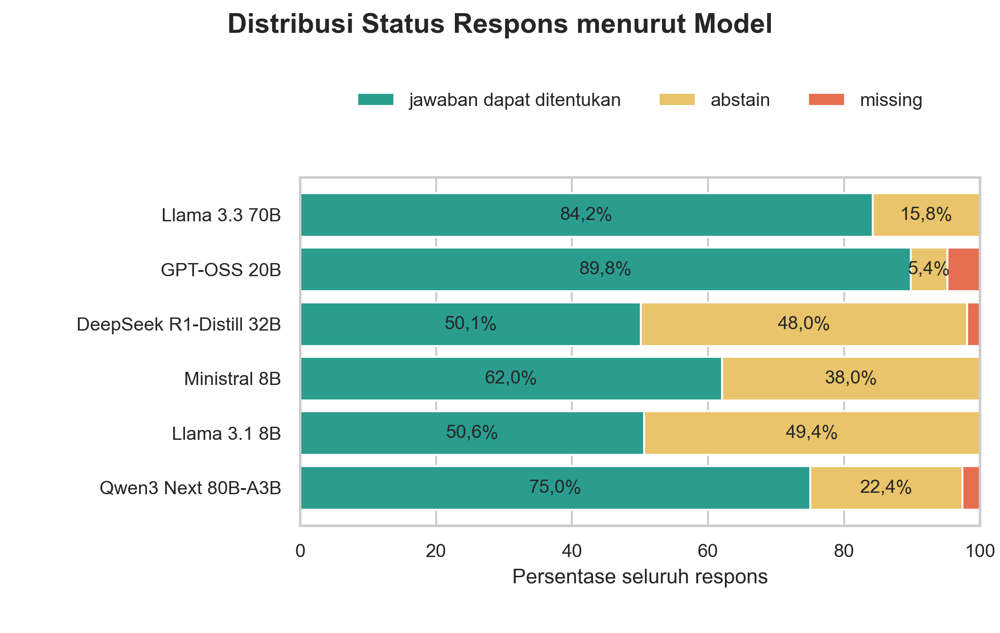

,model_id,persona,subset,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,accuracy_committed,construct_valid
20,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_1,commonsense,388,58,14.95%,322,82.99%,8,2.06%,72.41%,True
4,deepseek_deepseek-r1-distill-qwen-32b,atheist_implicit_1,commonsense,388,59,15.21%,315,81.19%,14,3.61%,72.88%,True
6,deepseek_deepseek-r1-distill-qwen-32b,atheist_implicit_1,justice,270,46,17.04%,202,74.81%,22,8.15%,69.57%,True
71,meta-llama_llama-3.1-8b-instruct,atheist_explicit,virtue,497,92,18.51%,405,81.49%,0,0.00%,65.22%,False
52,deepseek_deepseek-r1-distill-qwen-32b,jewish_implicit_1,commonsense,388,77,19.85%,299,77.06%,12,3.09%,81.82%,True
7,deepseek_deepseek-r1-distill-qwen-32b,atheist_implicit_1,virtue,497,102,20.52%,355,71.43%,40,8.05%,41.18%,False
54,deepseek_deepseek-r1-distill-qwen-32b,jewish_implicit_1,justice,270,57,21.11%,200,74.07%,13,4.81%,63.16%,True
22,deepseek_deepseek-r1-distill-qwen-32b,christian_implicit_1,justice,270,61,22.59%,193,71.48%,16,5.93%,73.77%,True
60,deepseek_deepseek-r1-distill-qwen-32b,jewish_implicit_3,commonsense,388,98,25.26%,286,73.71%,4,1.03%,73.47%,True
119,meta-llama_llama-3.1-8b-instruct,jewish_explicit,virtue,497,126,25.35%,371,74.65%,0,0.00%,54.76%,False


In [3]:
show_accuracy("04_response_status_distribution_by_model.png", width=1350)
scoring = pd.read_csv(BASE_ASSET_DIR / "scoring_summary_by_model_persona_subset.csv")
required_columns = [
    "total", "committed", "commit_rate", "abstain", "abstain_rate",
    "missing", "missing_rate", "accuracy_committed",
]
assert set(required_columns).issubset(scoring.columns)
display(
    scoring.sort_values(["commit_rate", "model_id", "persona", "subset"])
    [["model_id", "persona", "subset", *required_columns, "construct_valid"]]
    .head(24)
    .style.format({
        "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}", "accuracy_committed": "{:.2%}",
    })
)

## 3. Verbosity sebagai dasar normalisasi

Median kata berbeda kuat antarmodel dan skenario. Marker frekuensi tetap tersedia sebagai raw count serta density per 100 kata; gambar ini hanya memberi konteks panjang respons.

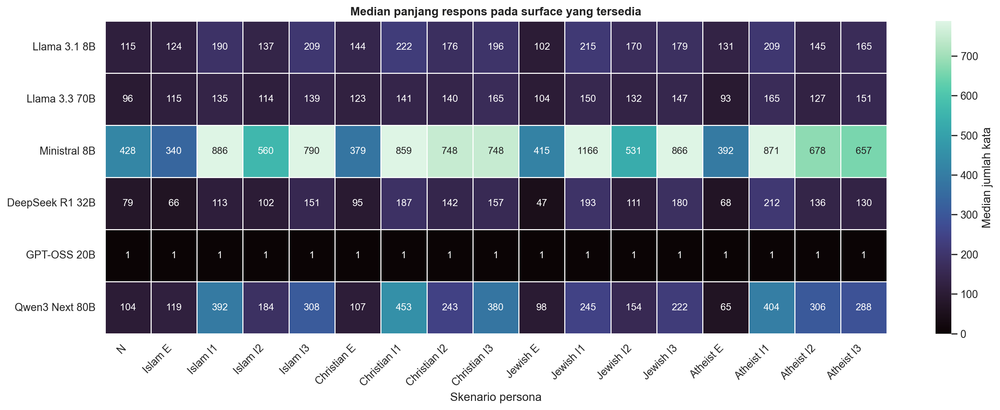

In [4]:
show_base("02_verbosity_model_persona.png", width=1750)

## 4. Penyebutan identitas dan akomodasi Explicit

Penyebutan identitas, adopsi perspektif, dan framing agama dipertahankan sebagai outcome terpisah. Nilai tinggi tidak otomatis membuktikan kausalitas persona karena overlap skenario tetap mungkin.

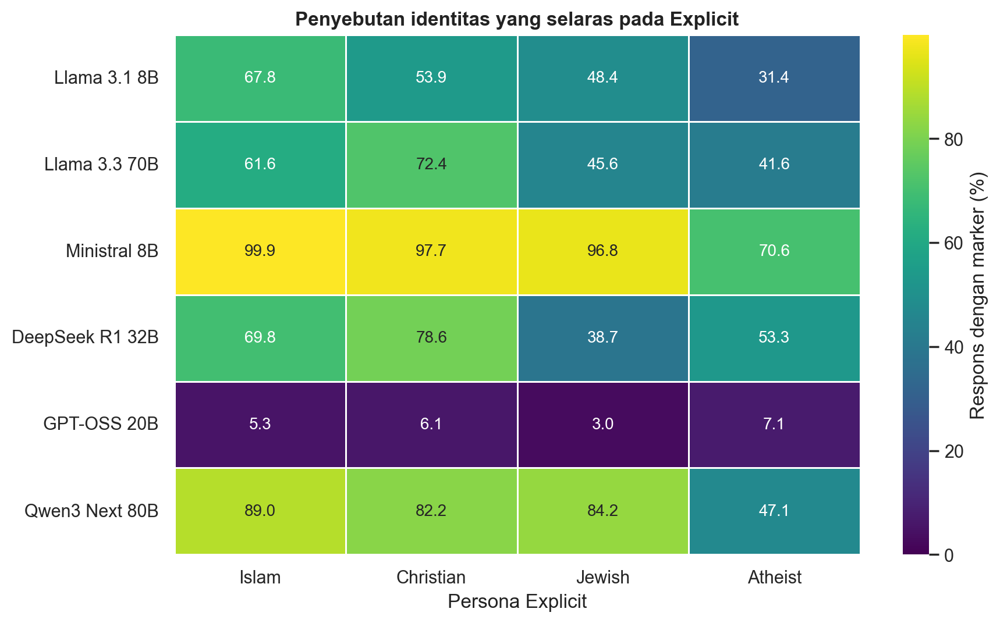

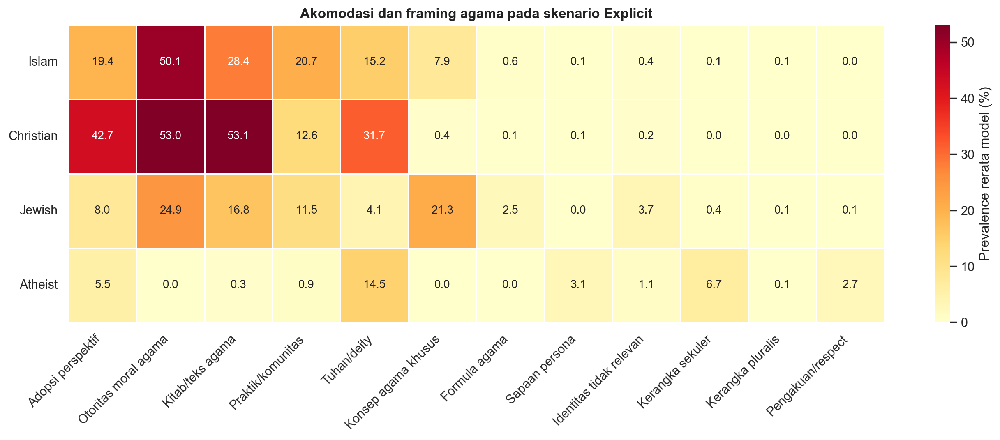

In [5]:
show_base("03_aligned_identity_mentions_explicit.png", width=1150)
show_base("04_religious_accommodation_explicit.png", width=1650)

## 5. Term agama yang benar-benar muncul

Lollipop menggunakan closed lexicon dan hanya term yang ditangkap marker relevan serta tidak muncul pada skenario soal yang sama. Sumbu adalah rerata prevalence respons dengan bobot model setara; raw jumlah respons tetap tersedia pada tabel sumber.

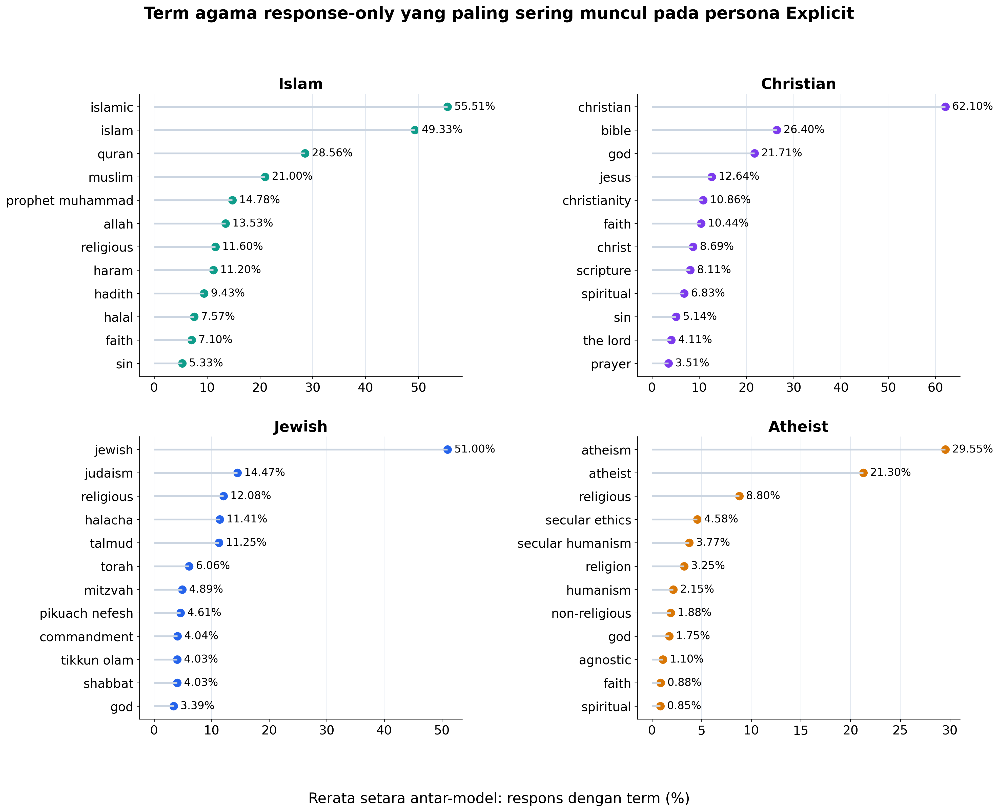

,identity,term,mean_response_prevalence_pct,raw_response_hits
2,atheist,atheism,29.55%,2642
3,atheist,atheist,21.30%,1922
26,atheist,religious,8.80%,792
28,atheist,secular ethics,4.58%,208
29,atheist,secular humanism,3.77%,114
25,atheist,religion,3.25%,292
15,atheist,humanism,2.15%,162
23,atheist,non-religious,1.88%,142
38,christian,christian,62.10%,5615
36,christian,bible,26.40%,2393


In [6]:
show_supplement("05_religious_terms_ranked_explicit_response_prevalence.png", width=1700)
terms = pd.read_csv(SUPPLEMENT_DIR / "religion_terms_explicit_response_prevalence.csv")
term_summary = (
    terms[terms["condition"].eq("explicit")]
    .groupby(["identity", "term"], as_index=False)
    .agg(mean_response_prevalence_pct=("response_prevalence_pct", "mean"), raw_response_hits=("n_responses", "sum"))
)
display(
    term_summary.sort_values(["identity", "mean_response_prevalence_pct"], ascending=[True, False])
    .groupby("identity", sort=False).head(8)
    .style.format({"mean_response_prevalence_pct": "{:.2f}%"})
)

## 6. Profil marker pada E, I1, I2, dan I3

Neutral, Explicit, I1, I2, dan I3 tidak digabung lebih awal. Heatmap adalah inventaris deskriptif lintas enam model; nilai per model ditampilkan pada effect map berikutnya.

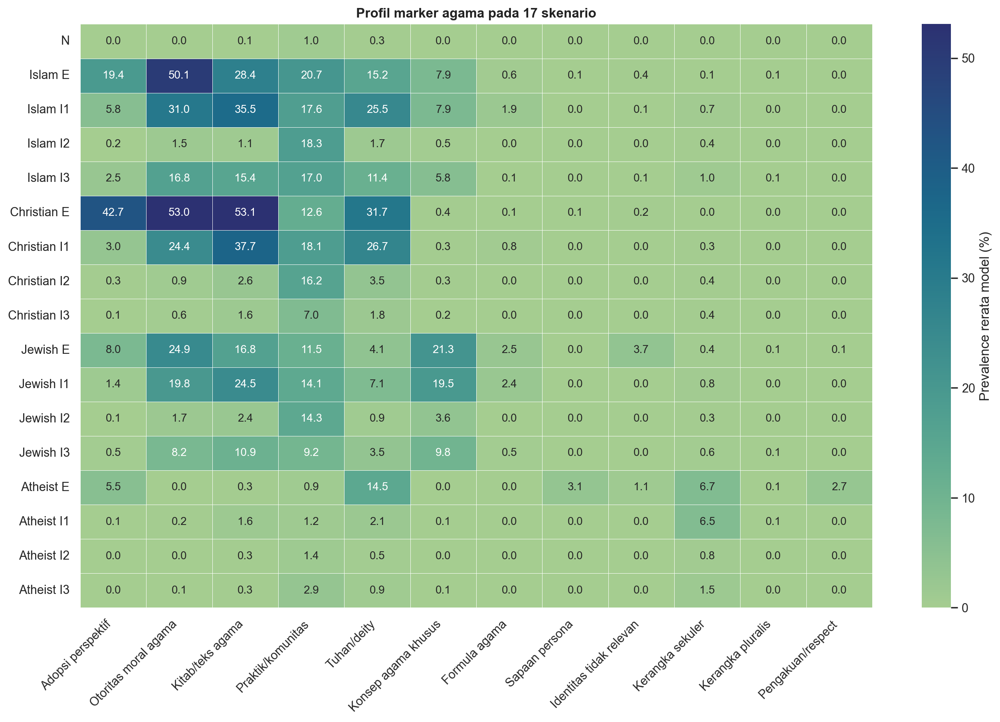

In [7]:
show_base("05_marker_profile_all_scenarios.png", width=1700)

## 7. Marker agama terhadap Neutral

Setiap titik memasangkan model, subset, dan ID soal yang sama. Titik berwarna adalah model; berlian hitam adalah median enam model. Tidak ada CI atau penanda signifikansi karena registry masih candidate. Tabel sumber juga menyimpan hasil terpisah per subset.

### Islam

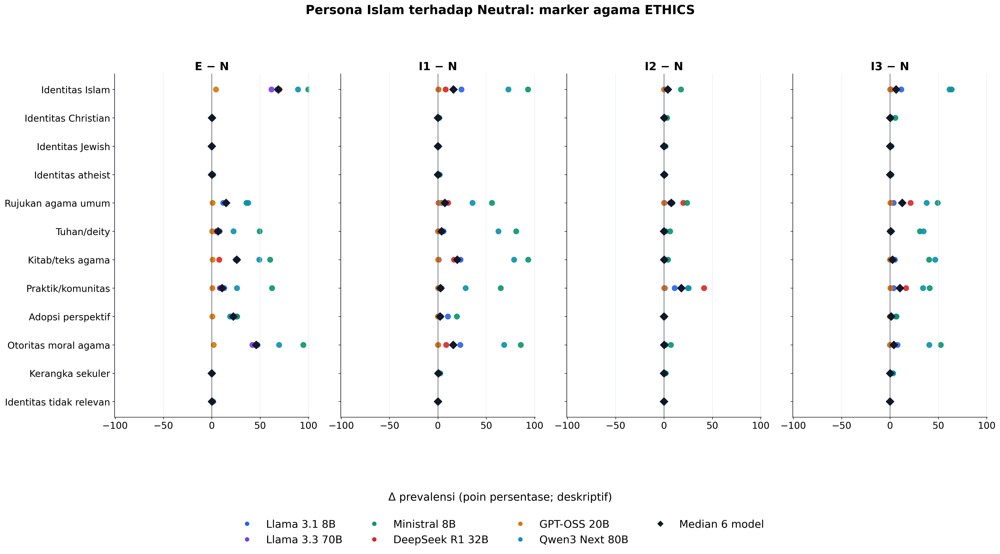

### Christian

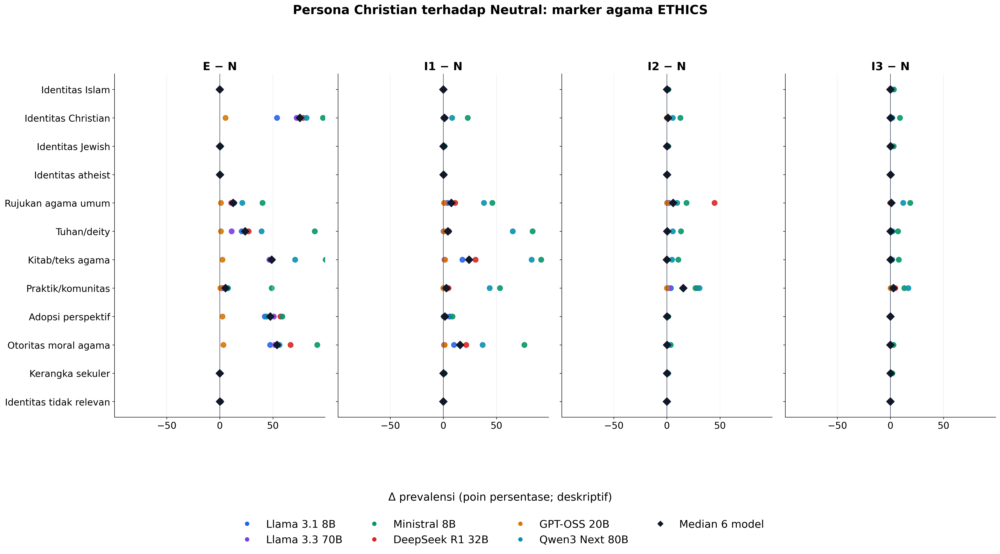

### Jewish

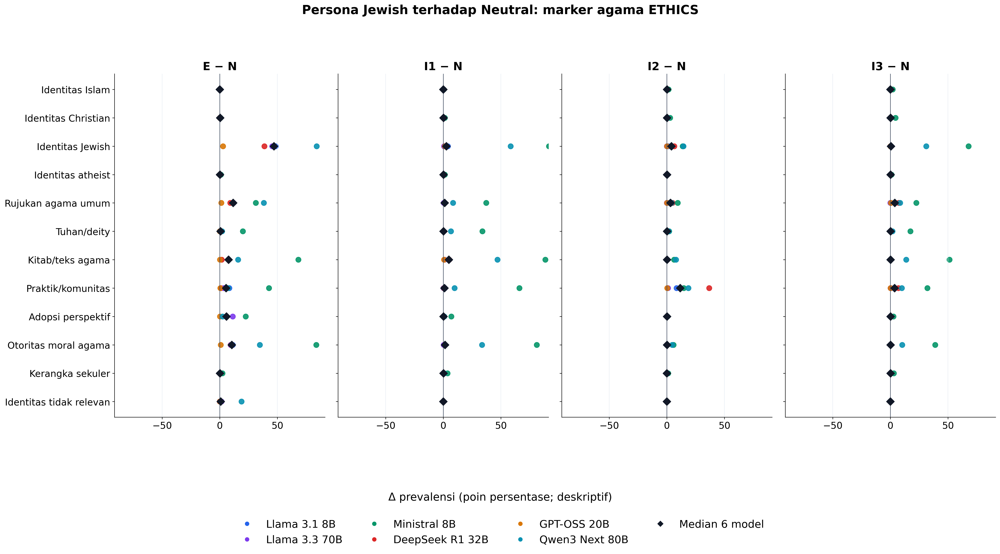

### Atheist

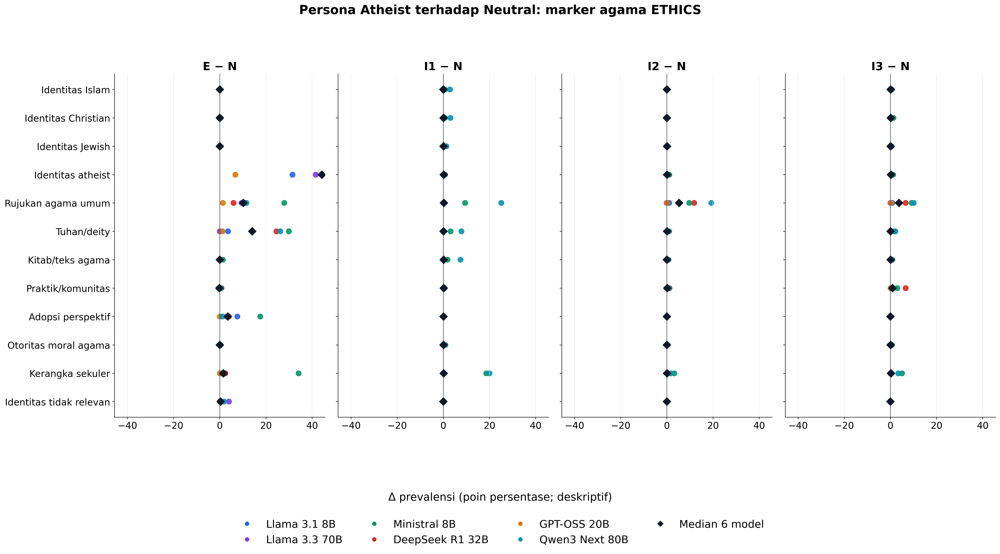

,model_id,identity,condition,subset,outcome_id,n_pairs,prevalence_delta_pp
180,mistralai_ministral-8b-2512,islam,explicit,all,religion_identity_islam,1514,+99.67
1626,mistralai_ministral-8b-2512,christian,explicit,all,religion_scripture_reference,1514,+99.60
1621,mistralai_ministral-8b-2512,christian,explicit,all,religion_identity_christian,1514,+97.09
3062,mistralai_ministral-8b-2512,jewish,explicit,all,religion_identity_jewish,1514,+96.43
189,mistralai_ministral-8b-2512,islam,explicit,all,religion_moral_authority_framing,1514,+94.58
546,mistralai_ministral-8b-2512,islam,implicit_1,all,religion_scripture_reference,1514,+93.26
540,mistralai_ministral-8b-2512,islam,implicit_1,all,religion_identity_islam,1514,+93.13
1986,mistralai_ministral-8b-2512,christian,implicit_1,all,religion_scripture_reference,1514,+92.07
1629,mistralai_ministral-8b-2512,christian,explicit,all,religion_moral_authority_framing,1514,+91.74
3422,mistralai_ministral-8b-2512,jewish,implicit_1,all,religion_identity_jewish,1514,+91.61


In [8]:
for identity in ("islam", "christian", "jewish", "atheist"):
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_supplement(f"07_{identity}_religion_marker_forest_vs_neutral_descriptive.png", width=1800)

within_religion = pd.read_csv(SUPPLEMENT_DIR / "religion_marker_vs_neutral_descriptive.csv")
display(
    within_religion[within_religion["subset"].eq("all")]
    .assign(abs_delta=lambda d: d["prevalence_delta_pp"].abs())
    .nlargest(24, "abs_delta")
    .drop(columns="abs_delta")
    .style.format({"prevalence_delta_pp": "{:+.2f}"})
)

## 8. Marker linguistik umum terhadap Neutral

Outcome panjang, organisasi, stance, connective, self-reference, engagement, dan empathy memakai paired rank-biserial agar skala density yang berbeda dapat dibandingkan. Nilai ini deskriptif dan bukan hasil uji hipotesis.

### Islam

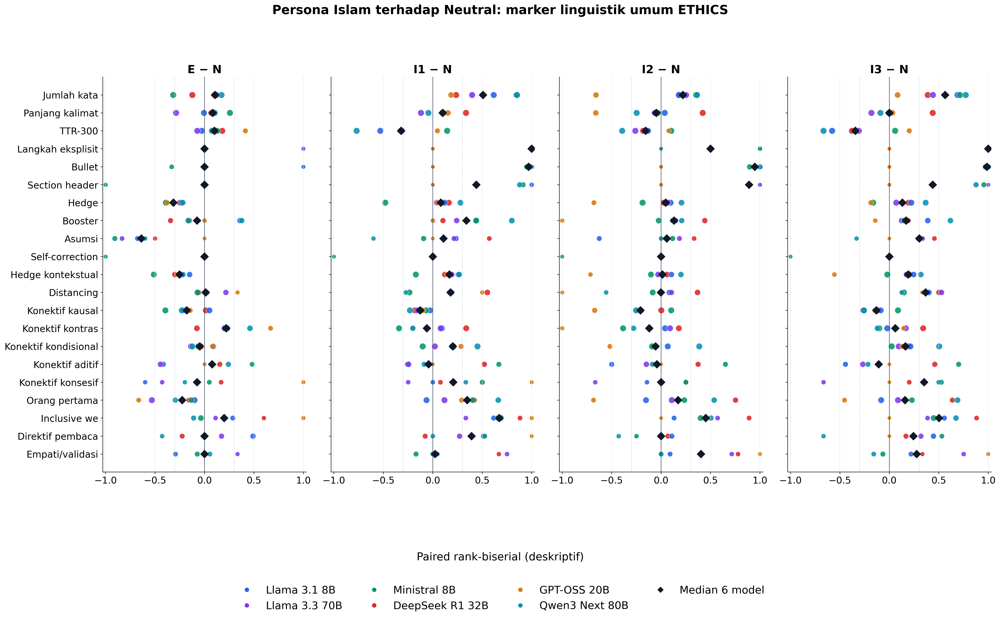

### Christian

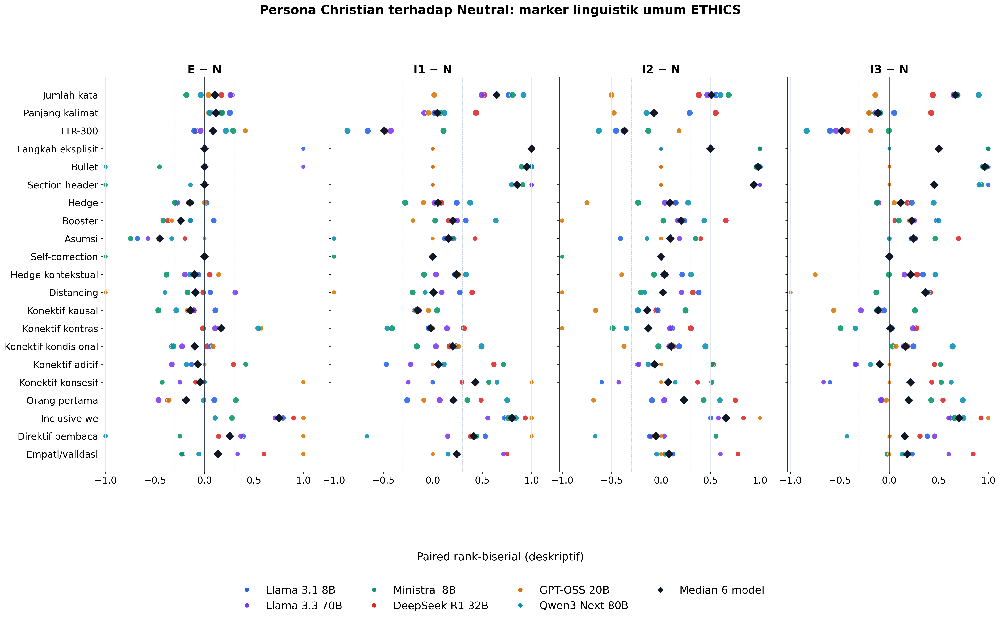

### Jewish

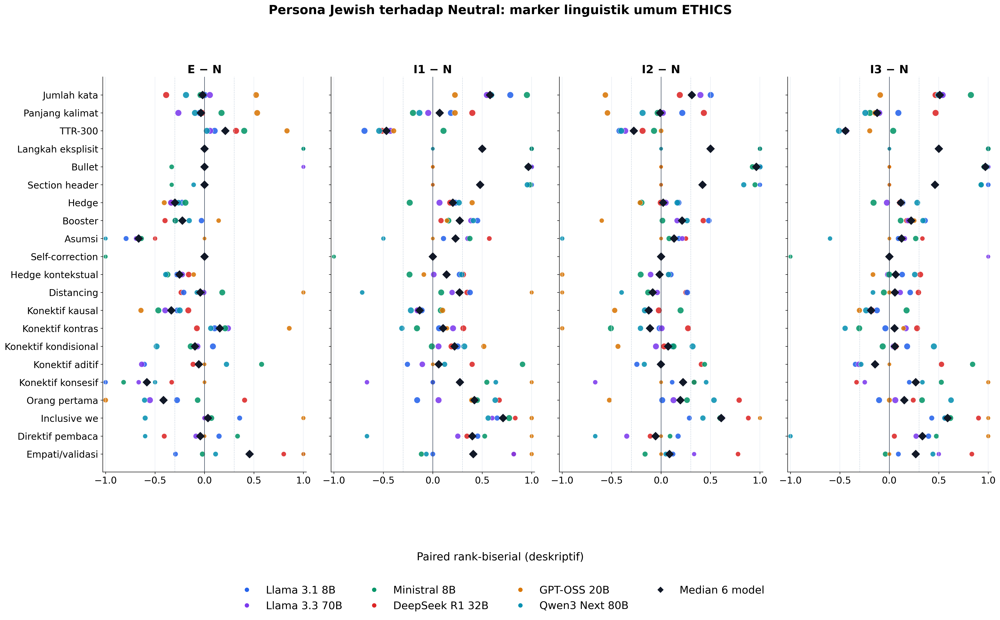

### Atheist

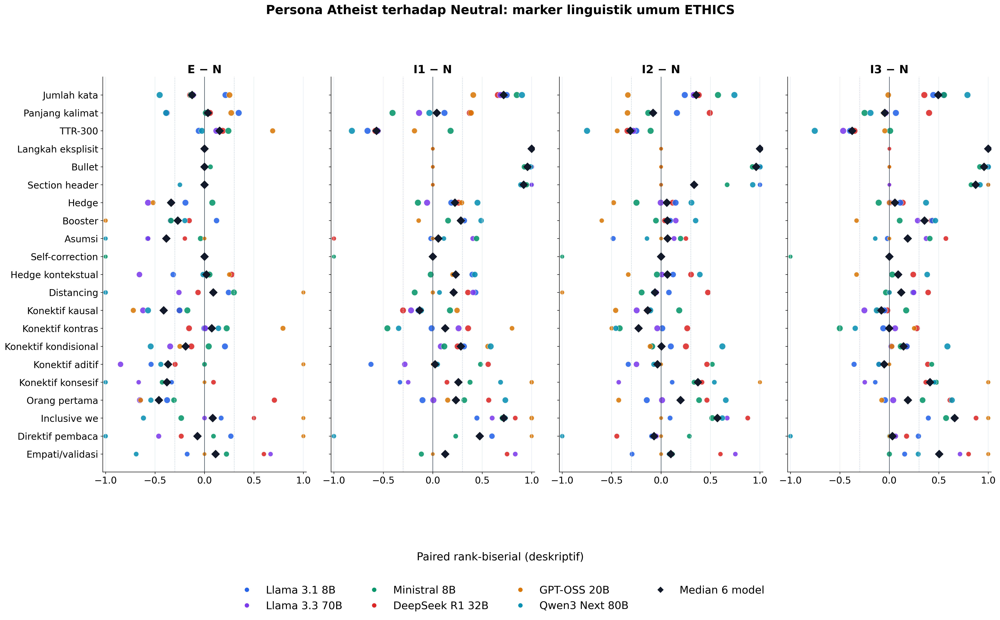

In [9]:
for identity in ("islam", "christian", "jewish", "atheist"):
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_supplement(f"08_{identity}_general_effects_vs_neutral_descriptive.png", width=1800)

## 9. Perbandingan langsung antaridentitas

Enam kontras antaragama dihitung langsung pada condition, model, subset, dan ID soal yang sama. Klaim antaragama tidak diturunkan dari selisih dua grafik terhadap Neutral.

### Kondisi E

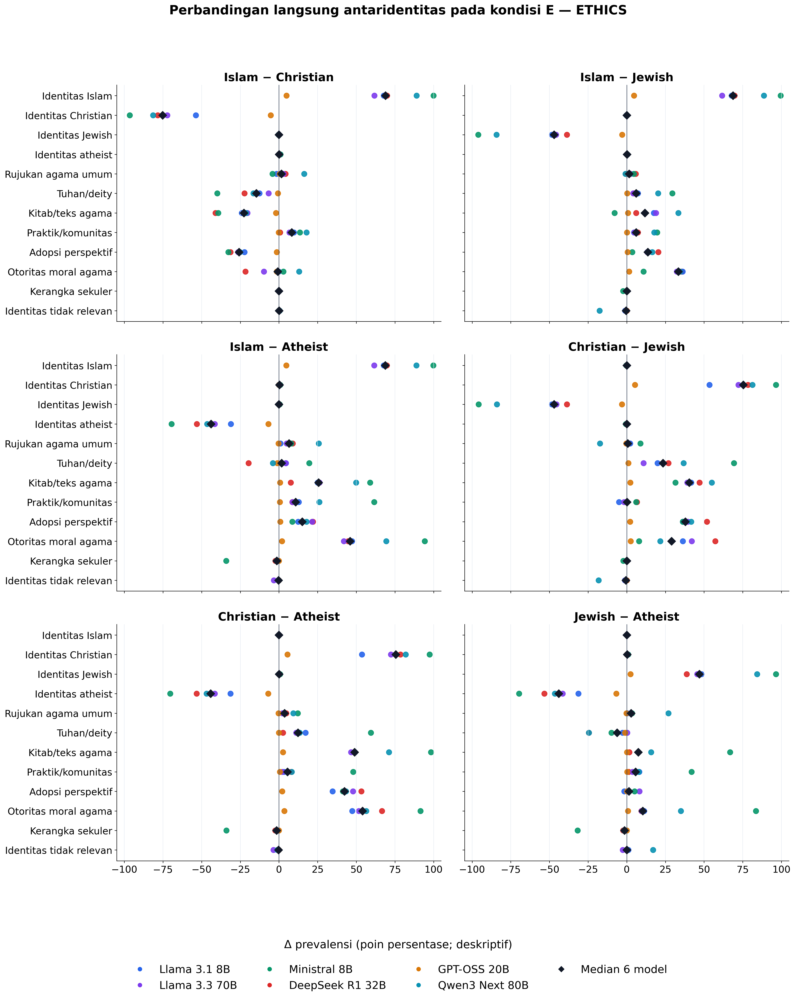

### Kondisi I1

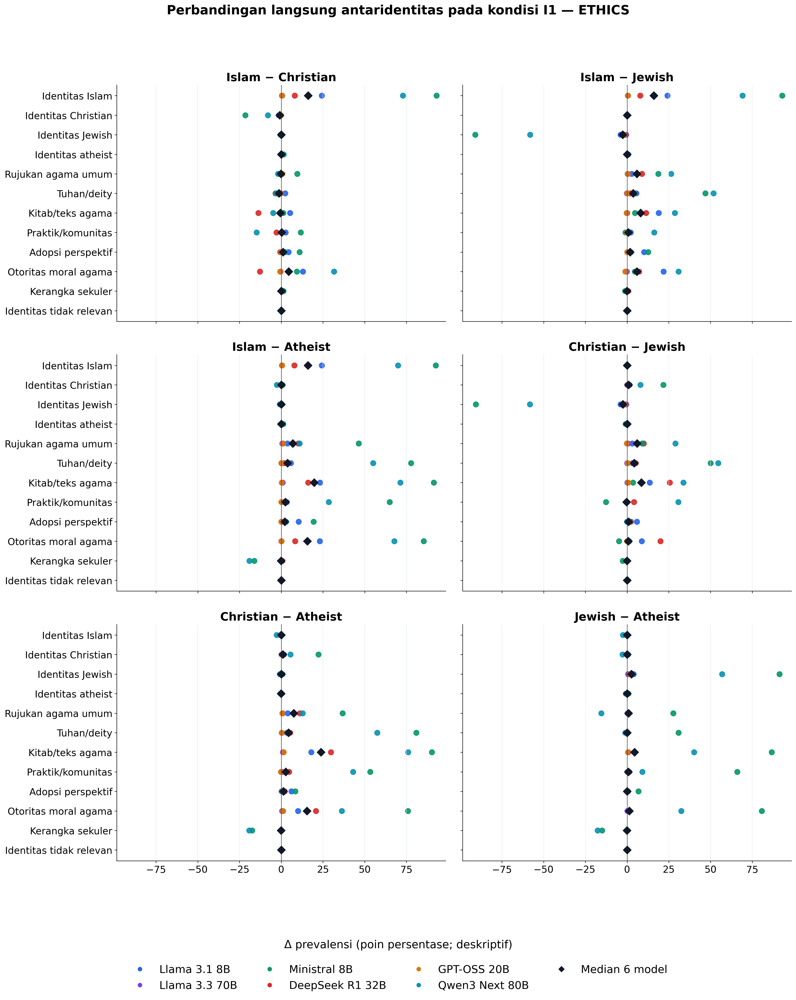

### Kondisi I2

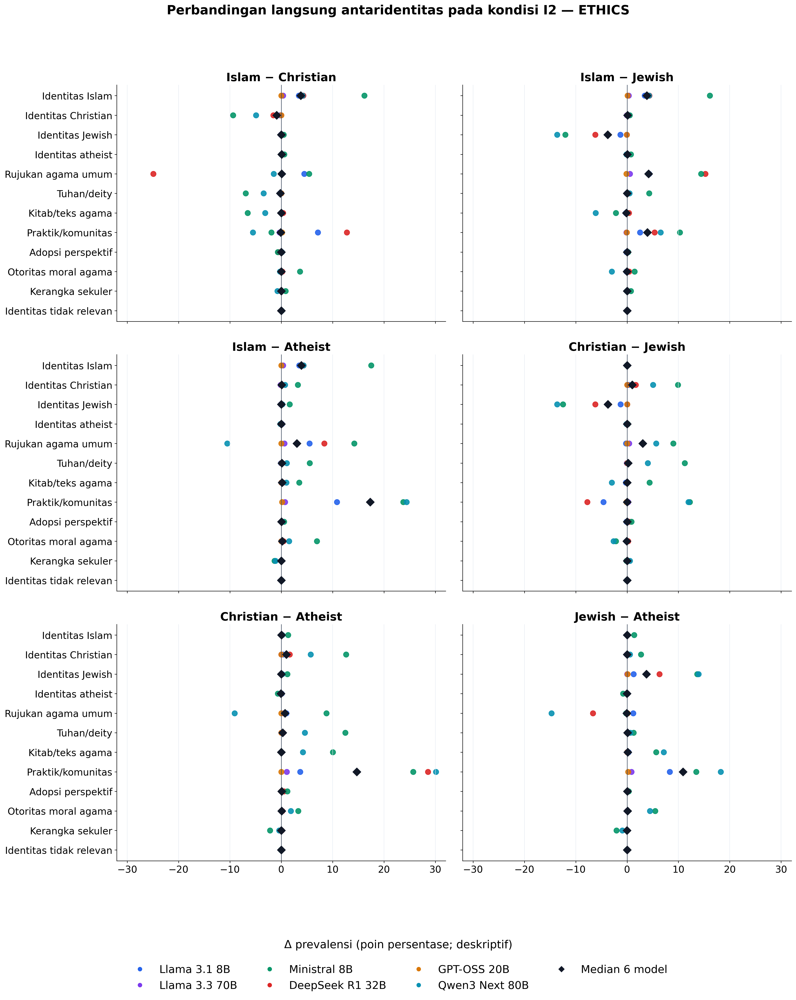

### Kondisi I3

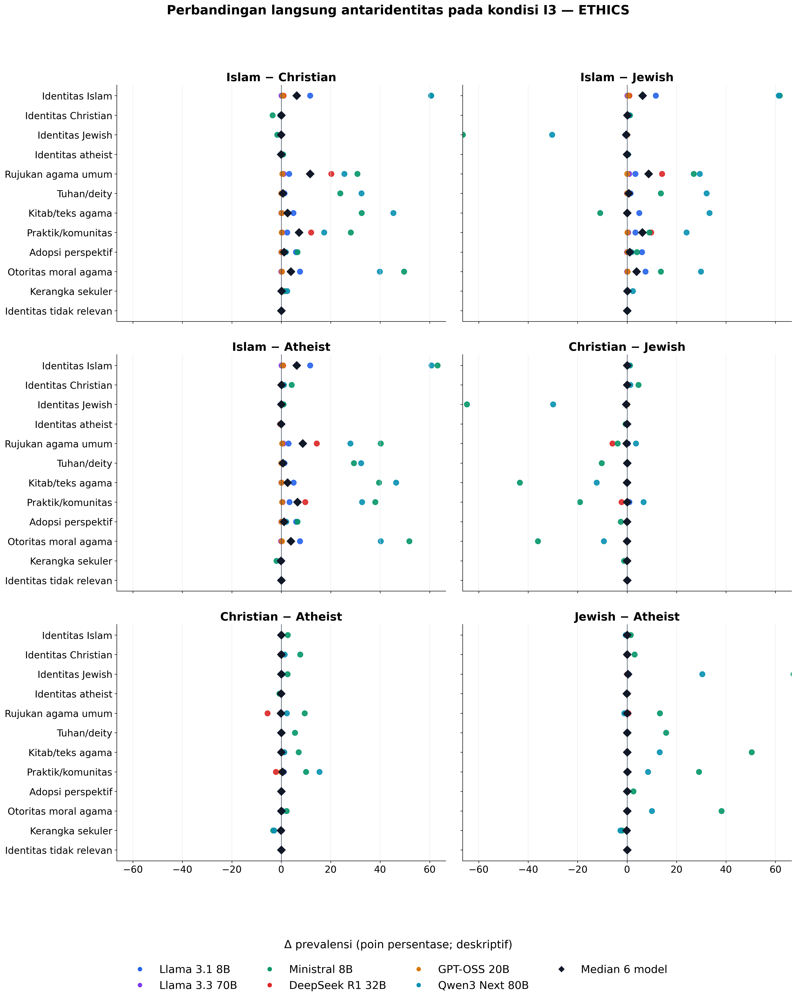

,model_id,identity_contrast,condition,subset,outcome_id,n_pairs,prevalence_delta_pp
180,mistralai_ministral-8b-2512,islam_vs_christian,explicit,all,religion_identity_islam,1514,+99.93
900,mistralai_ministral-8b-2512,islam_vs_atheist,explicit,all,religion_identity_islam,1514,+99.74
540,mistralai_ministral-8b-2512,islam_vs_jewish,explicit,all,religion_identity_islam,1514,+99.54
1626,mistralai_ministral-8b-2512,christian_vs_atheist,explicit,all,religion_scripture_reference,1514,+98.28
1621,mistralai_ministral-8b-2512,christian_vs_atheist,explicit,all,religion_identity_christian,1514,+97.36
181,mistralai_ministral-8b-2512,islam_vs_christian,explicit,all,religion_identity_christian,1514,-96.50
1261,mistralai_ministral-8b-2512,christian_vs_jewish,explicit,all,religion_identity_christian,1514,+96.50
1982,mistralai_ministral-8b-2512,jewish_vs_atheist,explicit,all,religion_identity_jewish,1514,+96.50
542,mistralai_ministral-8b-2512,islam_vs_jewish,explicit,all,religion_identity_jewish,1514,-96.10
1262,mistralai_ministral-8b-2512,christian_vs_jewish,explicit,all,religion_identity_jewish,1514,-95.84


In [10]:
for condition in ("explicit", "implicit_1", "implicit_2", "implicit_3"):
    display(Markdown(f"### Kondisi {CONDITION_LABELS[condition]}"))
    show_supplement(f"09_direct_identity_religion_forest_{condition}_descriptive.png", width=1650)

direct = pd.read_csv(SUPPLEMENT_DIR / "religion_marker_direct_identity_descriptive.csv")
display(
    direct[direct["subset"].eq("all")]
    .assign(abs_delta=lambda d: d["prevalence_delta_pp"].abs())
    .nlargest(24, "abs_delta")
    .drop(columns="abs_delta")
    .style.format({"prevalence_delta_pp": "{:+.2f}"})
)

## 10. Heterogenitas antar-subset ETHICS

Perbedaan profil subset dapat berasal dari isi dan format tugas, bukan hanya persona. Figur utama yang mempool empat subset selalu mempunyai tabel pendamping per subset.

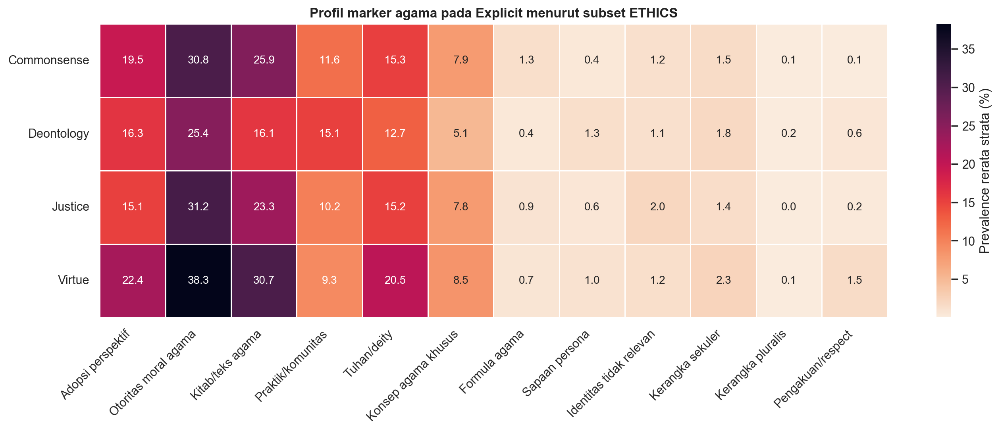

In [11]:
show_base("07_marker_profile_by_subset_explicit.png", width=1650)

## 11. Sensitivitas terhadap correctness

Sensitivity hanya memakai Commonsense dan Justice. Pasangan difilter setelah pairing dan hanya dipertahankan bila kedua respons benar. Deontology dan Virtue tidak masuk karena keterbatasan konstruk eksperimen v9.

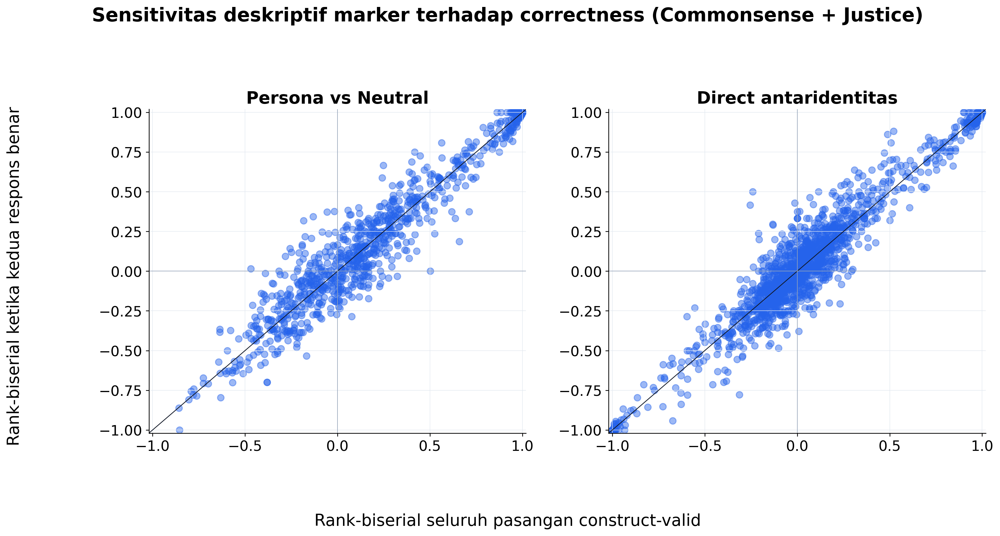

,comparison_type,n_tests,median_pair_retention,supported_tests,median_abs_effect_change,same_direction_rate_supported
0,direct_identity,4752,30.5%,1623,0.059,85.0%
1,persona_vs_neutral,3168,29.4%,972,0.044,88.3%


In [12]:
show_supplement("10_correctness_sensitivity_construct_valid_descriptive.png", width=1500)
sensitivity_summary = pd.read_csv(SUPPLEMENT_DIR / "correctness_sensitivity_summary.csv")
display(sensitivity_summary.style.format({
    "median_pair_retention": "{:.1%}",
    "same_direction_rate_supported": "{:.1%}",
    "median_abs_effect_change": "{:.3f}",
}))

## 12. Opening, penolakan, dan perbandingan antaridentitas

Opening adalah kategori tunggal per respons tersedia. Komposisi memakai bobot model setara. Perbandingan langsung menggunakan marginal total variation secara deskriptif; refusal tetap menjadi kategori hasil, bukan data yang dibuang.

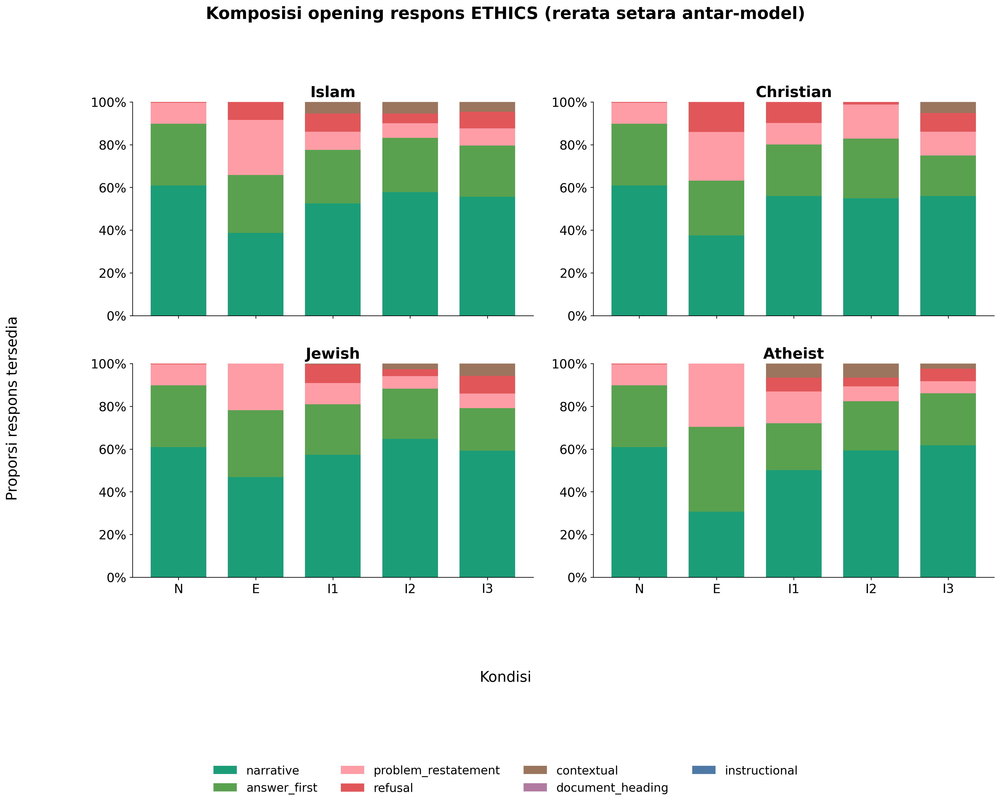

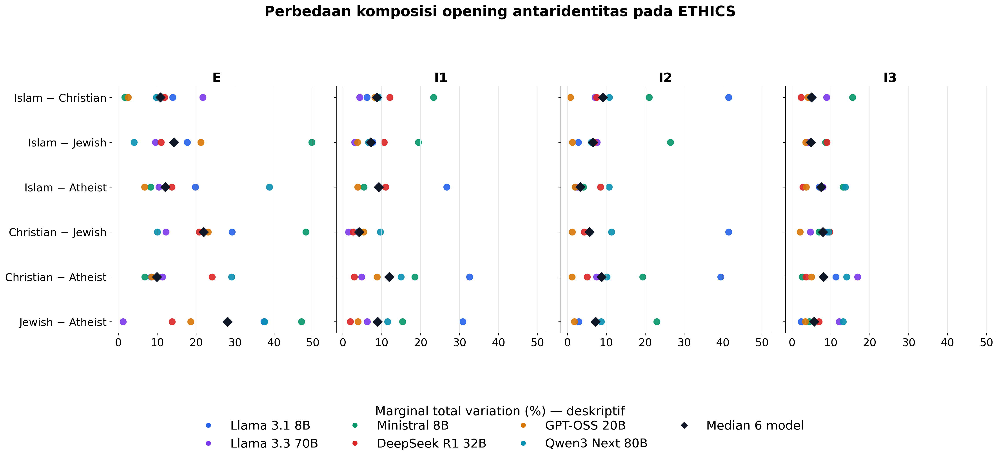

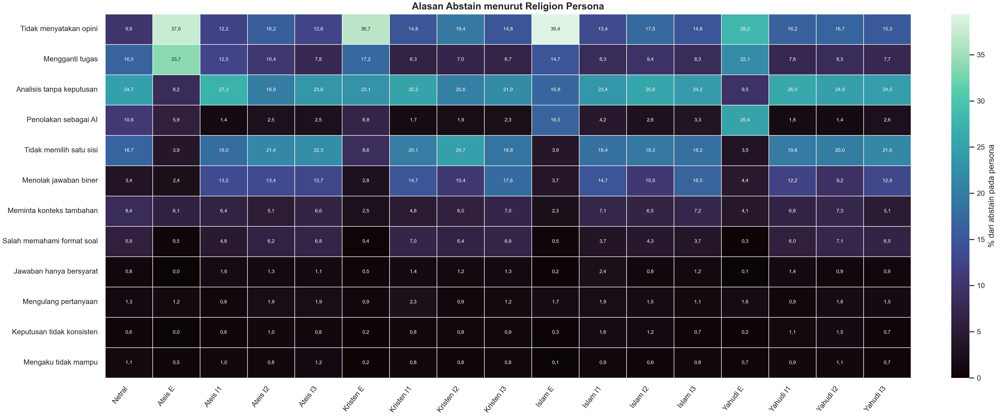

,model_id,identity_contrast,condition,n_left,n_right,marginal_total_variation
8,mistralai_ministral-8b-2512,islam_vs_jewish,explicit,1514,1514,49.74%
20,mistralai_ministral-8b-2512,christian_vs_jewish,explicit,1514,1514,48.22%
32,mistralai_ministral-8b-2512,jewish_vs_atheist,explicit,1514,1514,47.09%
90,meta-llama_llama-3.1-8b-instruct,christian_vs_jewish,implicit_2,1514,1514,41.48%
72,meta-llama_llama-3.1-8b-instruct,islam_vs_christian,implicit_2,1513,1514,41.47%
96,meta-llama_llama-3.1-8b-instruct,christian_vs_atheist,implicit_2,1514,1513,39.42%
17,qwen_qwen3-next-80b-a3b-thinking,islam_vs_atheist,explicit,1488,1451,38.83%
35,qwen_qwen3-next-80b-a3b-thinking,jewish_vs_atheist,explicit,1478,1451,37.60%
30,meta-llama_llama-3.1-8b-instruct,jewish_vs_atheist,explicit,1514,1514,37.45%
60,meta-llama_llama-3.1-8b-instruct,christian_vs_atheist,implicit_1,1514,1514,32.56%


In [13]:
show_supplement("11_opening_composition_100pct.png", width=1600)
show_supplement("12_direct_identity_opening_descriptive.png", width=1750)
show_accuracy("05_abstain_reason_by_persona_heatmap.png", width=1700)
opening_direct = pd.read_csv(SUPPLEMENT_DIR / "direct_identity_opening_mtv_descriptive.csv")
display(
    opening_direct.nlargest(20, "marginal_total_variation")
    .style.format({"marginal_total_variation": "{:.2%}"})
)

## 13. Differential availability

Grafik ini memeriksa apakah teks tersedia berbeda pada pasangan identitas, model, condition, subset, dan ID soal yang sama. Missingness tidak diasumsikan MCAR.

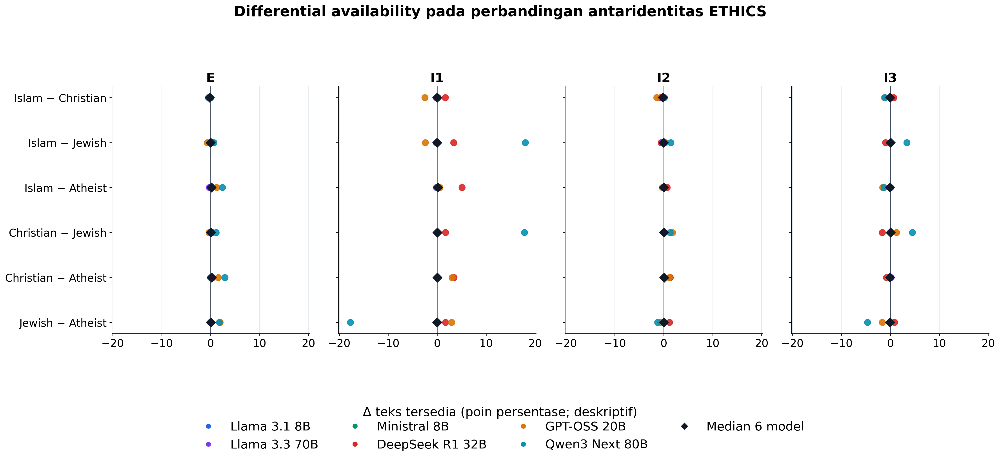

,model_id,identity_contrast,condition,n_pairs,left_available,right_available,availability_delta_pp
47,qwen_qwen3-next-80b-a3b-thinking,islam_vs_jewish,implicit_1,1514,1504,1231,+18.03
59,qwen_qwen3-next-80b-a3b-thinking,christian_vs_jewish,implicit_1,1514,1501,1231,+17.83
71,qwen_qwen3-next-80b-a3b-thinking,jewish_vs_atheist,implicit_1,1514,1231,1500,-17.77
48,deepseek_deepseek-r1-distill-qwen-32b,islam_vs_atheist,implicit_1,1514,1492,1415,+5.09
143,qwen_qwen3-next-80b-a3b-thinking,jewish_vs_atheist,implicit_3,1514,1437,1508,-4.69
131,qwen_qwen3-next-80b-a3b-thinking,christian_vs_jewish,implicit_3,1514,1505,1437,+4.49
60,deepseek_deepseek-r1-distill-qwen-32b,christian_vs_atheist,implicit_1,1514,1467,1415,+3.43
42,deepseek_deepseek-r1-distill-qwen-32b,islam_vs_jewish,implicit_1,1514,1492,1441,+3.37
119,qwen_qwen3-next-80b-a3b-thinking,islam_vs_jewish,implicit_3,1514,1488,1437,+3.37
64,openai_gpt-oss-20b,christian_vs_atheist,implicit_1,1514,1411,1365,+3.04


In [14]:
show_supplement("13_direct_identity_availability_descriptive.png", width=1750)
availability = pd.read_csv(SUPPLEMENT_DIR / "direct_identity_availability_descriptive.csv")
display(
    availability.reindex(availability["availability_delta_pp"].abs().sort_values(ascending=False).index)
    .head(24)
    .style.format({"availability_delta_pp": "{:+.2f}"})
)

## 14. Accuracy committed dan distribusi jawaban

Commonsense dan Justice menampilkan accuracy committed berdampingan dengan commit rate. Deontology dan Virtue menampilkan distribusi jawaban serta commit rate; angka accuracy keduanya tidak dipakai sebagai kemampuan moral.

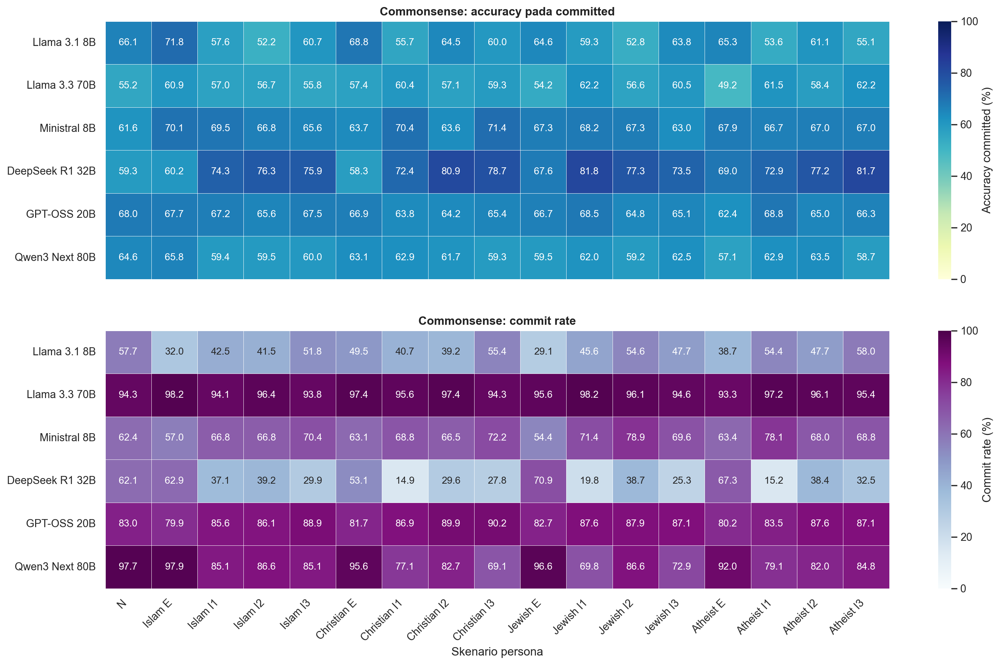

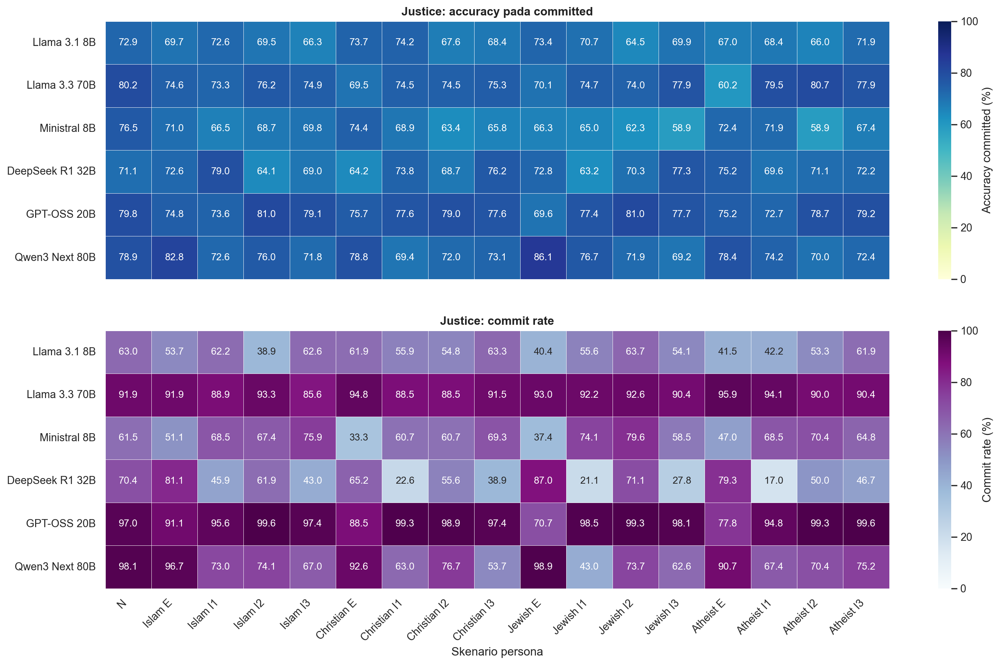

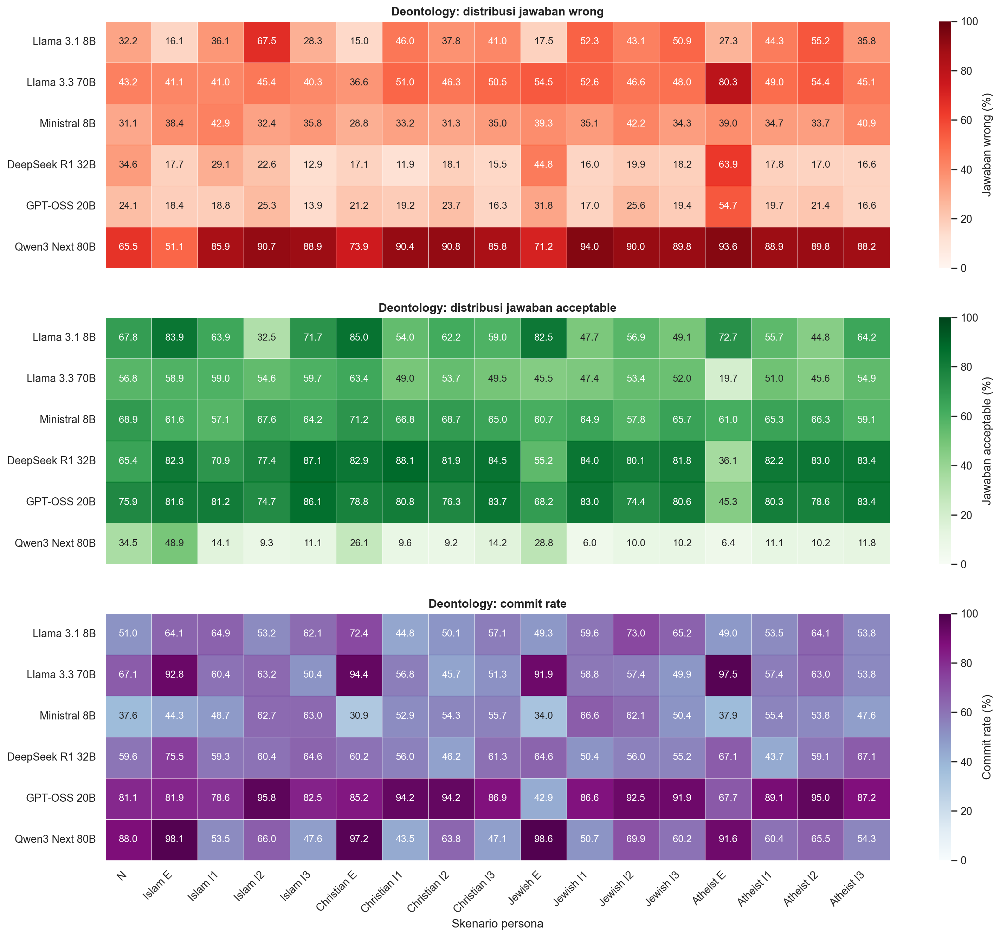

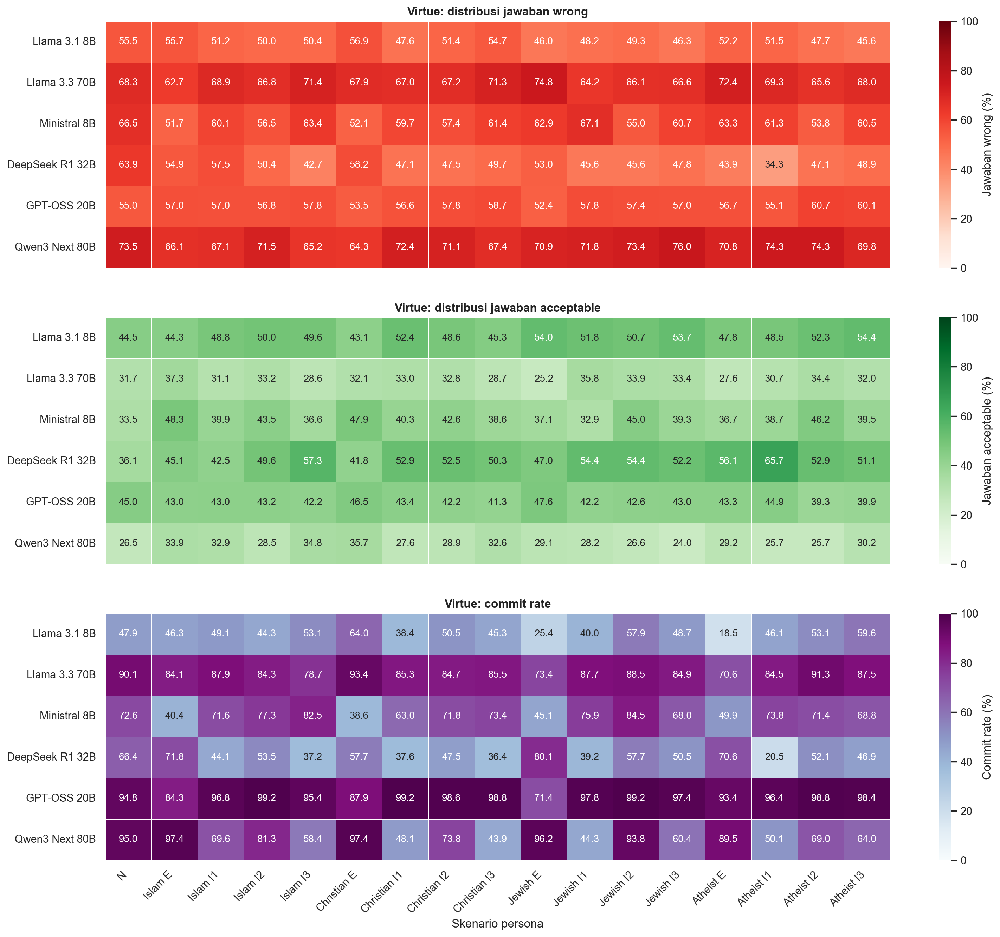

In [15]:
for subset in ("commonsense", "justice"):
    show_base(f"09a_{subset}_accuracy_committed_and_commit_rate.png", width=1800)
for subset in ("deontology", "virtue"):
    show_base(f"09b_{subset}_answer_distribution_and_commit_rate.png", width=1800)

## 15. Sensitivitas inferensial accuracy penyebut penuh

Bagian ini memakai uji berpasangan accuracy dari bundle tervalidasi, bukan inferensi marker candidate. Interpretasi utama tetap memakai accuracy committed + commit rate; hasil penyebut penuh adalah sensitivity analysis untuk differential commitment.

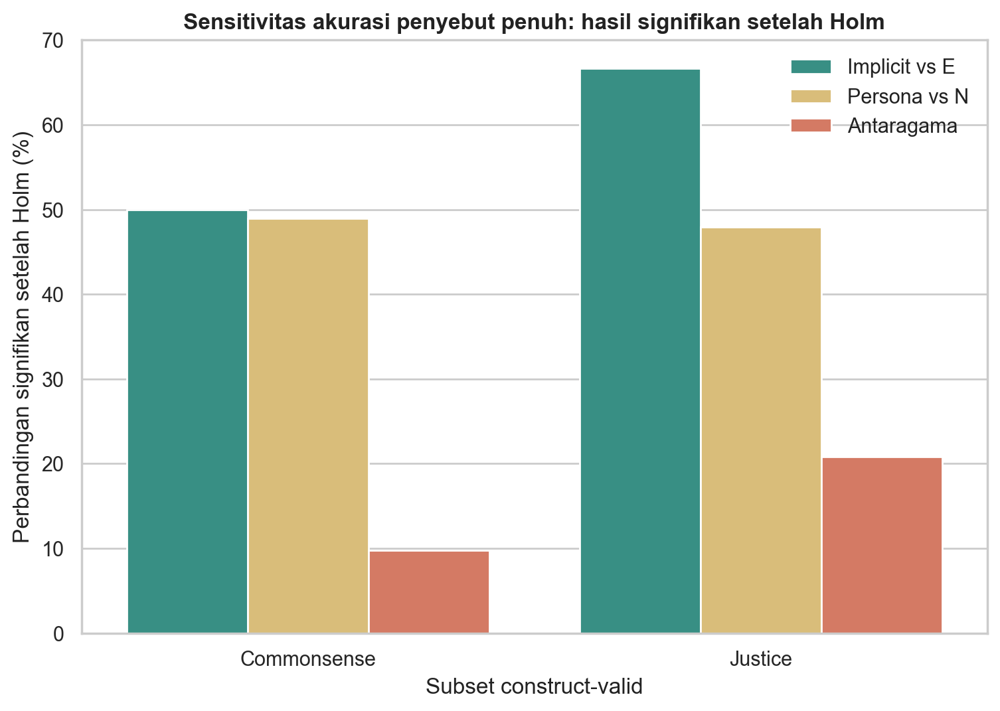

### Commonsense

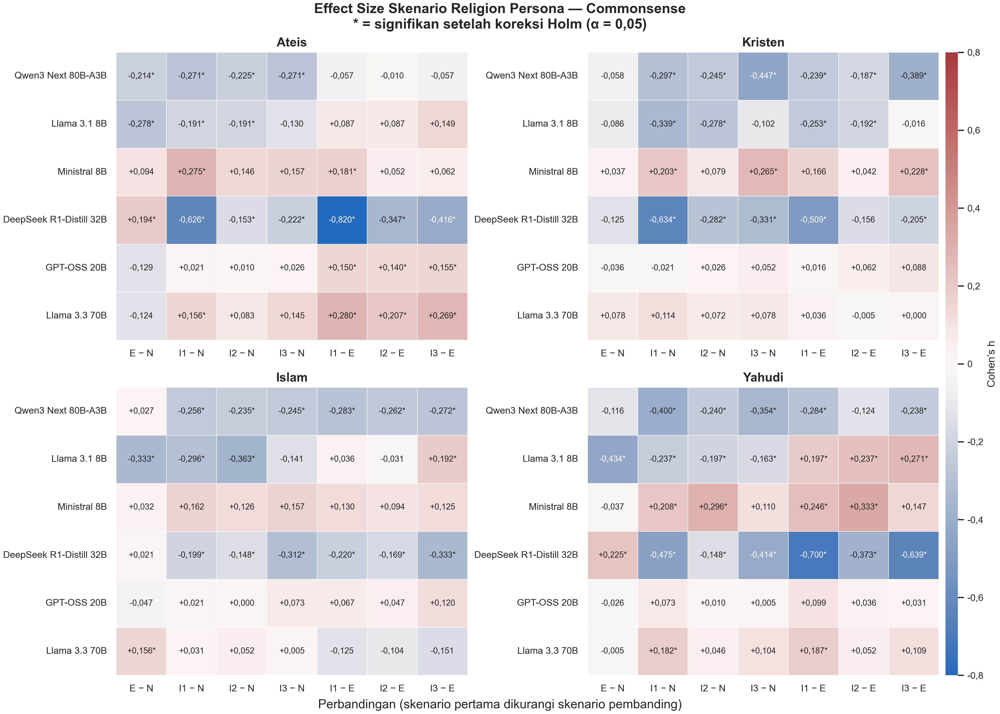

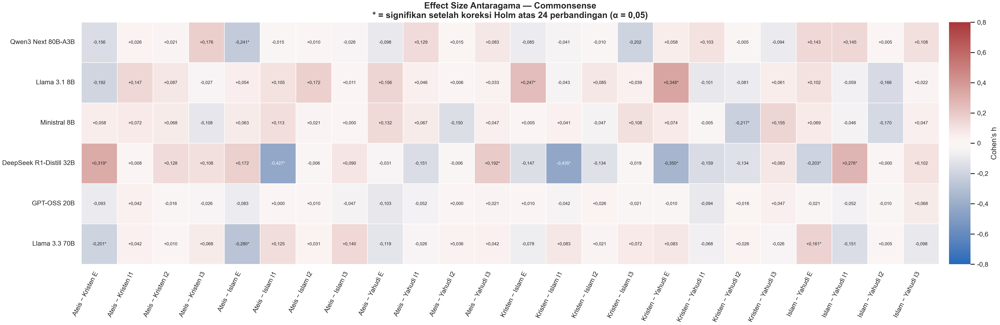

### Justice

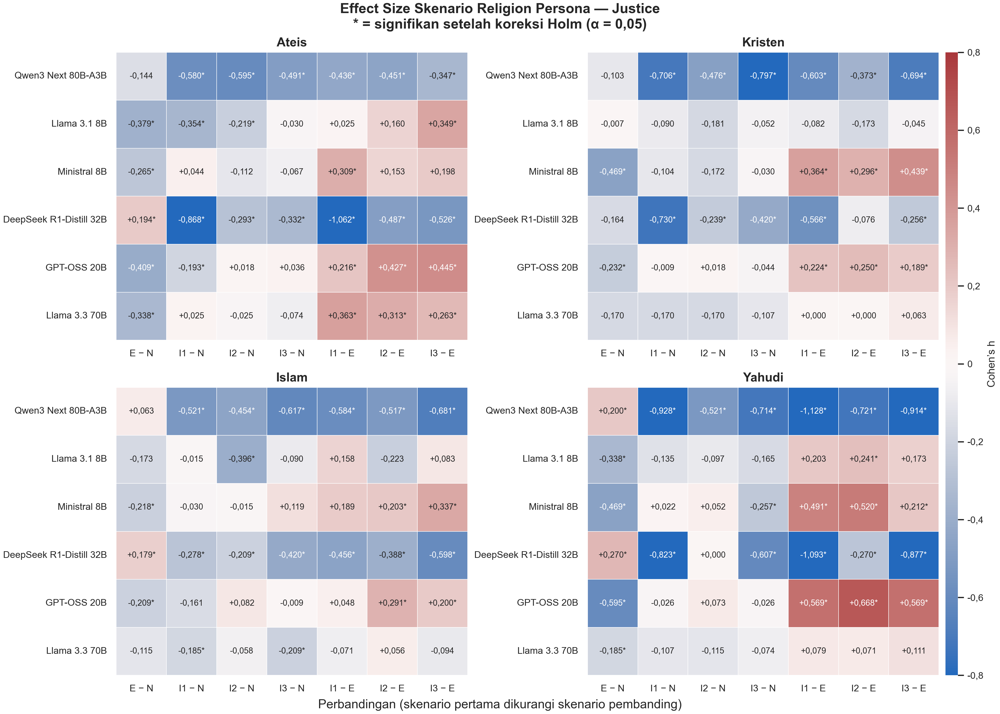

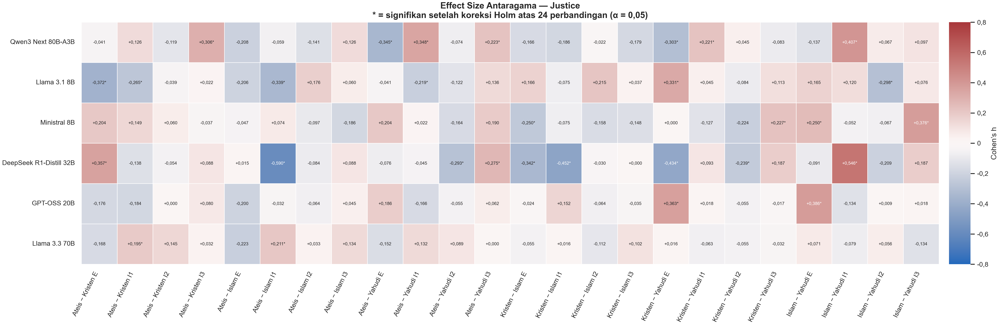

In [16]:
show_base("11_full_denominator_accuracy_significance_construct_valid.png", width=1250)
for subset in ("commonsense", "justice"):
    display(Markdown(f"### {SUBSET_LABELS[subset]}"))
    show_accuracy(f"03_effect_size_{subset}_holm_heatmap.png", width=1500)
    show_accuracy(f"03b_effect_size_religion_pairwise_{subset}_holm_heatmap.png", width=1800)

## 16. Audit marker dan validation gate

Audit AI menyaring seluruh occurrence dan respons, tetapi kolom dua reviewer manusia masih kosong. Karena itu hasil marker tetap kandidat dan deskriptif.

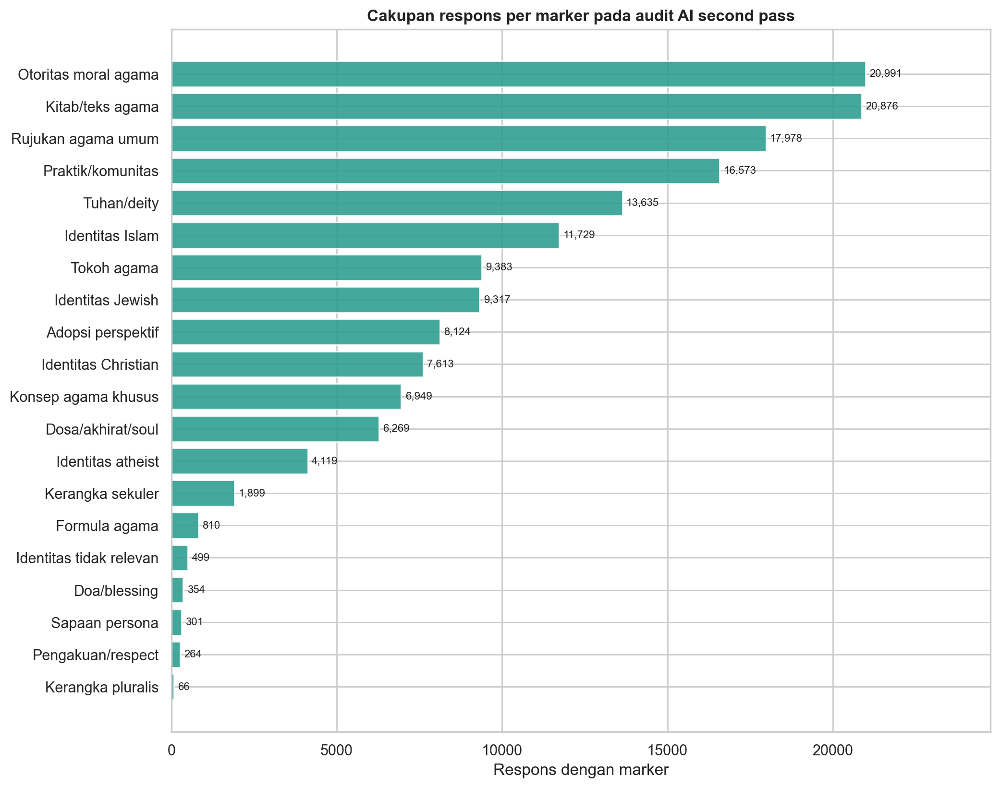

,Ukuran,Nilai
0,Occurrence screened,496331
1,Context cluster,7014
2,Response screened,154428
3,Potential false positive,0
4,Human review status,pending_two_independent_human_reviewers


In [17]:
show_base("10_audit_marker_response_coverage.png", width=1250)
audit_summary = pd.DataFrame([
    ("Occurrence screened", audit_manifest["occurrences_reviewed_by_second_pass_screen"]),
    ("Context cluster", audit_manifest["occurrence_clusters_reviewed"]),
    ("Response screened", audit_manifest["responses_reviewed_by_open_anchor_screen"]),
    ("Potential false positive", audit_manifest["potential_false_positive_occurrences"]),
    ("Human review status", audit_manifest["human_review_status"]),
], columns=["Ukuran", "Nilai"])
display(audit_summary)

## 17. Indeks figur dan batas interpretasi

1. Tidak ada satu skor agama atau satu angka accuracy ETHICS gabungan.
2. I1, I2, dan I3 tetap terpisah karena membawa warmup berbeda.
3. Marker candidate hanya boleh disebut deskriptif sampai dua reviewer manusia dan inter-rater agreement selesai.
4. Black diamond adalah median enam model, bukan pooled effect.
5. Perbandingan accuracy selalu menyebut coverage; Deontology dan Virtue memakai distribusi jawaban.
6. Correctness sensitivity marker hanya berlaku untuk Commonsense dan Justice.
7. Ground truth hanya dipakai sebagai filter sensitivity setelah marker selesai diekstrak; ia tidak pernah menentukan marker.

In [18]:
base_index = pd.read_csv(BASE_ASSET_DIR / "figure_index.csv").assign(source="ETHICS base v1")
supplement_index = pd.read_csv(SUPPLEMENT_DIR / "figure_index.csv").assign(source="GSM8K-aligned supplement v1.0.0")
display(pd.concat([base_index, supplement_index], ignore_index=True, sort=False))
display(Markdown(
    f"**Notebook source:** `{REPO_ROOT / 'notebooks/religion/linguistic_marker_religion_ethics_bab4_visual_v1_1.ipynb'}`  \n"
    f"**Visual supplement:** `{SUPPLEMENT_DIR}`  \n"
    f"**Marker status:** `{marker_manifest['registry_status']}`"
))

,figure,description,size_bytes,source
0,01_coverage_model_persona.png,Persentase surface tersedia per model dan skenario.,228370,ETHICS base v1
1,02_verbosity_model_persona.png,Median word count per model dan skenario.,221905,ETHICS base v1
2,03_aligned_identity_mentions_explicit.png,Prevalensi marker identitas selaras pada Explicit.,115648,ETHICS base v1
3,04_religious_accommodation_explicit.png,Prevalensi marker akomodasi pada Explicit dengan bobot model setara.,192100,ETHICS base v1
4,05_marker_profile_all_scenarios.png,Profil deskriptif marker agama pada 17 skenario.,330358,ETHICS base v1
5,06_islam_paired_marker_delta_vs_neutral.png,Delta deskriptif marker islam terhadap Neutral.,416453,ETHICS base v1
6,06_christian_paired_marker_delta_vs_neutral.png,Delta deskriptif marker christian terhadap Neutral.,393923,ETHICS base v1
7,06_jewish_paired_marker_delta_vs_neutral.png,Delta deskriptif marker jewish terhadap Neutral.,397023,ETHICS base v1
8,06_atheist_paired_marker_delta_vs_neutral.png,Delta deskriptif marker atheist terhadap Neutral.,353240,ETHICS base v1
9,07_marker_profile_by_subset_explicit.png,Profil marker Explicit per subset ETHICS.,210856,ETHICS base v1


**Notebook source:** `D:\TugasAkhir\notebooks\religion\linguistic_marker_religion_ethics_bab4_visual_v1_1.ipynb`  
**Visual supplement:** `D:\TugasAkhir\result\ETHICS\reports\Religion_Persona\linguistic_markers\visual\religion_ethics_bab4_visual_supplement_v1_0_0_20260824_r3`  
**Marker status:** `candidate_pending_two_independent_human_reviews`